# Neural Networks from Scratch: Perceptron and a One-Hidden-Layer MLP in NumPy
  A. Perceptron learning rule (step activation) on a 2-D binary dataset, run from three random
     initialisations to show how much the starting weights matter
  B. A 4-5-3 feed-forward network (tanh hidden layer, softmax output, MSE loss) trained with
     per-sample SGD on Iris; forward and backward passes written by hand

Run from this folder:  python neural_networks_from_scratch.py   (figures are written to ./figures)

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else "."
DATA = os.path.join(HERE, "data")
FIG = os.path.join(HERE, "figures")
os.makedirs(FIG, exist_ok=True)

BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#6b6b6b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})

## A. Perceptron

seed  42: init [ 0.3047 -1.04    0.7505] -> final [0.1947 0.0284 1.06  ] | accuracy 100% | first error-free pass: 17
seed   7: init [ 0.0012  0.2987 -0.2741] -> final [ 0.0112  0.3837 -0.0626] | accuracy 100% | first error-free pass: 4
seed 123: init [-0.9891 -0.3678  1.2879] -> final [-0.6891  0.1898  1.364 ] | accuracy 95% | first error-free pass: None


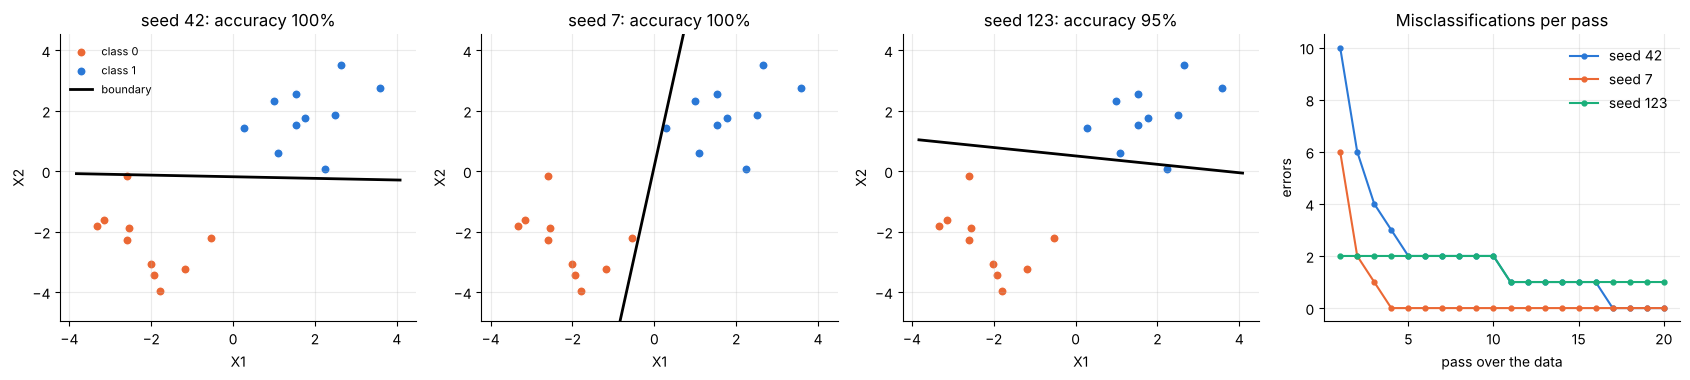

In [2]:
df = pd.read_csv(os.path.join(DATA, "perceptron_2d.csv"))
X, y = df[["X1", "X2"]].values, df["y"].values
Xb = np.c_[np.ones(len(X)), X]                       # bias input x0 = 1


def step(z):
    return (z >= 0).astype(float)


def train_perceptron(Xb, y, lr=0.01, n_iter=20, seed=None):
    rng = np.random.default_rng(seed)
    w = rng.standard_normal(3)                       # random initialisation [w0, w1, w2]
    w_init = w.copy()
    errors = []
    for _ in range(n_iter):                          # one iteration = one pass over all samples
        n_err = 0
        for xi, yi in zip(Xb, y):
            e = yi - step(xi @ w)
            n_err += int(e != 0)
            w = w + lr * e * xi                      # perceptron update rule
        errors.append(n_err)
    return w_init, w, errors


SEEDS = [42, 7, 123]
runs = {}
for s in SEEDS:
    w0, w, errs = train_perceptron(Xb, y, seed=s)
    acc = np.mean(step(Xb @ w) == y)
    first_zero = next((i + 1 for i, e in enumerate(errs) if e == 0), None)
    runs[s] = dict(w0=w0, w=w, errors=errs, acc=acc, converged_at=first_zero)
    print(f"seed {s:>3}: init {np.round(w0, 4)} -> final {np.round(w, 4)} | accuracy {acc * 100:.0f}% | "
          f"first error-free pass: {first_zero}")

fig, axes = plt.subplots(1, 4, figsize=(17, 3.9))
x1g = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 100)
for ax, s in zip(axes[:3], SEEDS):
    w = runs[s]["w"]
    ax.scatter(X[y == 0, 0], X[y == 0, 1], color=ORANGE, edgecolors="white", s=45, label="class 0")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], color=BLUE, edgecolors="white", s=45, label="class 1")
    ax.plot(x1g, -(w[0] + w[1] * x1g) / w[2], color="black", lw=2, label="boundary")
    ax.set_ylim(X[:, 1].min() - 1, X[:, 1].max() + 1)
    ax.set(title=f"seed {s}: accuracy {runs[s]['acc'] * 100:.0f}%", xlabel="X1", ylabel="X2")
axes[0].legend(frameon=False, fontsize=8)
for s, c in zip(SEEDS, [BLUE, ORANGE, GREEN]):
    axes[3].plot(range(1, 21), runs[s]["errors"], "o-", ms=3.5, color=c, label=f"seed {s}")
axes[3].set(title="Misclassifications per pass", xlabel="pass over the data", ylabel="errors")
axes[3].legend(frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "perceptron.png"), dpi=160)
plt.show()

## B. One-hidden-layer network on Iris
Loss L = mean over samples and classes of (a2 - y)^2. Because the output is a softmax, the gradient
with respect to the logits needs the softmax Jacobian:  dL/dz2 = a2 * (g - sum(g * a2)),  g = dL/da2.


gradient check (relative error on W2): 2.20e-09


epoch    1: train loss 0.2221 | test loss 0.2213 | train acc 40.0% | test acc 50.0%
epoch   10: train loss 0.1554 | test loss 0.1558 | train acc 66.7% | test acc 66.7%
epoch   50: train loss 0.0553 | test loss 0.0647 | train acc 95.0% | test acc 93.3%
epoch  100: train loss 0.0219 | test loss 0.0290 | train acc 97.5% | test acc 96.7%
epoch  250: train loss 0.0120 | test loss 0.0157 | train acc 97.5% | test acc 96.7%
epoch  500: train loss 0.0099 | test loss 0.0122 | train acc 98.3% | test acc 100.0%
epoch 1000: train loss 0.0089 | test loss 0.0105 | train acc 98.3% | test acc 100.0%
test confusion matrix (rows = true):
 [[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


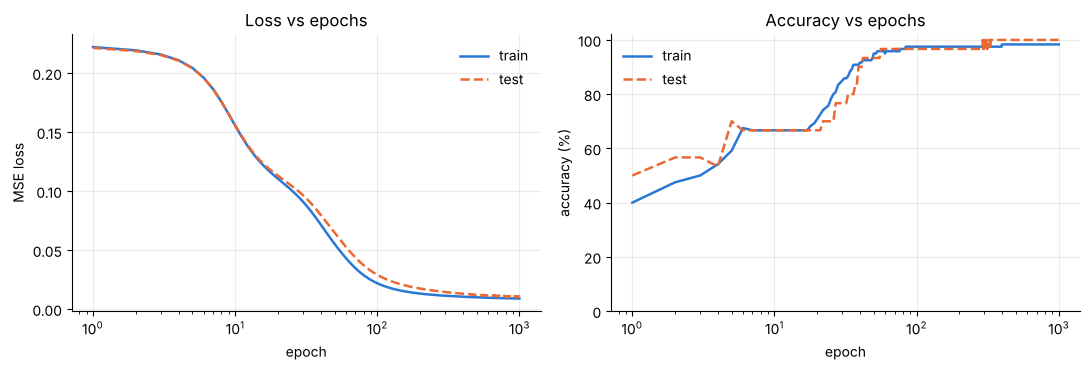

In [3]:
iris = load_iris()
Xi, yi = iris.data, iris.target
Yi = np.eye(3)[yi]
Xi_tr, Xi_te, Yi_tr, Yi_te, yi_tr, yi_te = train_test_split(Xi, Yi, yi, test_size=0.2, random_state=42,
                                                            stratify=yi)
sc = StandardScaler().fit(Xi_tr)
Xi_tr, Xi_te = sc.transform(Xi_tr), sc.transform(Xi_te)


def softmax(z):
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


class MLP:
    def __init__(self, n_in=4, n_hid=5, n_out=3, lr=0.01, seed=42):
        rng = np.random.default_rng(seed)
        self.W1 = rng.standard_normal((n_in, n_hid)) * 0.1
        self.b1 = np.zeros((1, n_hid))
        self.W2 = rng.standard_normal((n_hid, n_out)) * 0.1
        self.b2 = np.zeros((1, n_out))
        self.lr = lr

    def forward(self, X):
        self.X = X
        self.z1 = X @ self.W1 + self.b1
        self.a1 = np.tanh(self.z1)                         # hidden layer: tanh
        self.z2 = self.a1 @ self.W2 + self.b2
        self.a2 = softmax(self.z2)                         # output layer: softmax
        return self.a2

    def backward(self, Y):
        n, c = Y.shape
        g = 2.0 * (self.a2 - Y) / (n * c)                  # dL/da2 for the mean squared error
        dz2 = self.a2 * (g - np.sum(g * self.a2, axis=1, keepdims=True))   # through the softmax
        dW2, db2 = self.a1.T @ dz2, dz2.sum(axis=0, keepdims=True)
        dz1 = (dz2 @ self.W2.T) * (1.0 - self.a1 ** 2)     # tanh'(z) = 1 - tanh(z)^2
        dW1, db1 = self.X.T @ dz1, dz1.sum(axis=0, keepdims=True)
        for p, gp in [(self.W2, dW2), (self.b2, db2), (self.W1, dW1), (self.b1, db1)]:
            p -= self.lr * gp

    def fit(self, Xtr, Ytr, Xte, Yte, epochs=1000, seed=0):
        rng = np.random.default_rng(seed)
        hist = {k: [] for k in ["tr_loss", "te_loss", "tr_acc", "te_acc"]}
        for _ in range(epochs):
            for i in rng.permutation(len(Xtr)):           # SGD: one sample per update
                self.forward(Xtr[i:i + 1])
                self.backward(Ytr[i:i + 1])
            for split, Xs, Ys in [("tr", Xtr, Ytr), ("te", Xte, Yte)]:
                P = self.forward(Xs)
                hist[f"{split}_loss"].append(np.mean((P - Ys) ** 2))
                hist[f"{split}_acc"].append(np.mean(P.argmax(1) == Ys.argmax(1)) * 100)
        return hist


def grad_check(eps=1e-6):
    """Compare the analytic gradient with finite differences on a few samples."""
    net = MLP(seed=1, lr=0.0)
    Xs, Ys = Xi_tr[:5], Yi_tr[:5]
    net.forward(Xs)
    n, c = Ys.shape
    g = 2.0 * (net.a2 - Ys) / (n * c)
    dz2 = net.a2 * (g - np.sum(g * net.a2, axis=1, keepdims=True))
    analytic = net.a1.T @ dz2
    numeric = np.zeros_like(net.W2)
    for idx in np.ndindex(net.W2.shape):
        old = net.W2[idx]
        net.W2[idx] = old + eps
        lp = np.mean((net.forward(Xs) - Ys) ** 2)
        net.W2[idx] = old - eps
        lm = np.mean((net.forward(Xs) - Ys) ** 2)
        net.W2[idx] = old
        numeric[idx] = (lp - lm) / (2 * eps)
    return np.max(np.abs(analytic - numeric)) / (np.max(np.abs(numeric)) + 1e-12)


print(f"\ngradient check (relative error on W2): {grad_check():.2e}")

EPOCHS = 1000
net = MLP(lr=0.01, seed=42)
h = net.fit(Xi_tr, Yi_tr, Xi_te, Yi_te, epochs=EPOCHS)
for e in [1, 10, 50, 100, 250, 500, 1000]:
    print(f"epoch {e:>4}: train loss {h['tr_loss'][e - 1]:.4f} | test loss {h['te_loss'][e - 1]:.4f} | "
          f"train acc {h['tr_acc'][e - 1]:.1f}% | test acc {h['te_acc'][e - 1]:.1f}%")

P_te = net.forward(Xi_te).argmax(1)
cm = np.zeros((3, 3), dtype=int)
for t, p in zip(yi_te, P_te):
    cm[t, p] += 1
print("test confusion matrix (rows = true):\n", cm)

ep = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(ep, h["tr_loss"], color=BLUE, lw=1.8, label="train")
axes[0].plot(ep, h["te_loss"], color=ORANGE, lw=1.8, ls="--", label="test")
axes[0].set(xscale="log", xlabel="epoch", ylabel="MSE loss", title="Loss vs epochs")
axes[0].legend(frameon=False)
axes[1].plot(ep, h["tr_acc"], color=BLUE, lw=1.8, label="train")
axes[1].plot(ep, h["te_acc"], color=ORANGE, lw=1.8, ls="--", label="test")
axes[1].set(xscale="log", xlabel="epoch", ylabel="accuracy (%)", title="Accuracy vs epochs", ylim=(0, 102))
axes[1].legend(frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "mlp_iris_training.png"), dpi=160)
plt.show()